In [1]:
import torch, torchvision
from datasets import load_dataset
from torchvision import transforms

C:\Users\litwi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# CIFAR-10 image classifier in PyTorch

**Goal:** understand 100% of how a CNN is trained. We write the code as small **functions**, so each one can be reused, tested and explained.

**Data:** 60k color images, 32x32, 10 classes. Split: **45k train / 5k val / 10k test**. Decisions are made on validation; the test set is run **once, at the end**.

---

## Step 1: data
Write these functions, in this order:
1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`
2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch
3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)
4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`
5. `check_batch(loader)` → prints the shape of images and labels of one batch

**I understand it when I can explain:** the batch shape `(N, C, H, W)`, what a label is, why we need validation, why only train is shuffled.

## Step 2: MLP baseline and training loop
1. `get_device()` → returns `"cuda"`, `"mps"` or `"cpu"`
2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)
3. `count_parameters(model)` → returns the number of trainable parameters
4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss
5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy
6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict
7. `plot_history(history)` → plots train loss, val loss and val accuracy

**I understand it when I can explain:** each line of `train_one_epoch`, `backward()` vs `step()`, what `model.eval()` is for.

## Step 3: own CNN
1. `build_cnn()` → 3 blocks of Conv → BatchNorm → ReLU → MaxPool + Linear head
2. Before running: work out the shape after every layer on paper, then verify with `print(x.shape)`
3. Reuse `count_parameters`, `fit`, `plot_history` and compare with the MLP

**I understand it when I can explain:** where each shape comes from, why a CNN has fewer parameters than an MLP, what pooling does.

## Step 4: experiments (one change at a time)
1. `build_train_transform(augment)` → returns the transform with or without augmentation (`RandomCrop`, `RandomHorizontalFlip`)
2. `build_cnn(dropout)` → CNN with an optional dropout parameter
3. `run_experiment(name, **settings)` → builds, trains, returns val accuracy and parameters
4. Compare: augmentation yes/no, dropout yes/no, two learning rates; fill the table below

**I understand it when I can explain:** how to spot overfitting on a plot and how each regularization technique works.

## Step 5: transfer learning
1. `build_resnet18(num_classes=10, freeze=True)` → ImageNet weights, new last layer, optionally frozen body
2. Stage 1: train only the new layer (`fit`)
3. `unfreeze(model)` → makes all parameters trainable; Stage 2 with a small learning rate
4. `test_final(model, test_loader, device)` → run the test set **once**, for the single best model

**I understand it when I can explain:** why we freeze first, and why the unfrozen model uses a smaller learning rate.

---

## Results table

| Model / variant | Parameters | Val accuracy |
|---|---|---|
| MLP (baseline) | | |
| Own CNN | | |
| CNN + augmentation | | |
| CNN + dropout | | |
| ResNet18 (transfer learning) | | |

*Rough expectations (hypotheses): MLP 50-55%, CNN 75-80%, CNN + augmentation 80-85%, ResNet18 85%+.*

## Pass criteria
Working notebook, train/val plot, a table with at least four variants, I can answer the questions above without notes, and the test set was used exactly once.

## Step 1: data
## Write these functions, in this order:
1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`
2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch
3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)
4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`
5. `check_batch(loader)` → prints the shape of images and labels of one batch

**I understand it when I can explain:** the batch shape `(N, C, H, W)`, what a label is, why we need validation, why only train is shuffled.

## 1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`

In [2]:
def load_cifar():
    """Download CIFAR-10 from Hugging Face and return it as a DatasetDict."""
    ds = load_dataset("uoft-cs/cifar10")
    return ds

In [3]:
# Converter created once and reused for every image:
# PIL image -> tensor, layout (C, H, W), values scaled to 0-1
to_tensor = transforms.ToTensor()

example

In [4]:
ds = load_cifar()

In [5]:
sample = ds["train"][0]
print(type(sample["img"]), sample["img"].size, sample["label"])

<class 'PIL.PngImagePlugin.PngImageFile'> (32, 32) 0


In [6]:
x = to_tensor(sample["img"])
print(type(x), x.shape, x.dtype)
print(x.min(), x.max())

<class 'torch.Tensor'> torch.Size([3, 32, 32]) torch.float32
tensor(0.1333) tensor(0.7961)


## 2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch


In [71]:
def apply_transform(batch, transform):
    """Apply a torchvision transform to every PIL image in the batch."""
    batch["img"] = [transform(img) for img in batch["img"]]
    return batch

In [8]:
# with_transform registers apply_transform as a lazy "filter" on the dataset:
# - the stored data in ds stays unchanged (images are still PIL)
# - the function runs on the fly, only when rows are read (e.g. by a DataLoader)
# - it receives a dict of lists (a batch) and must return the same dict
# - good for random augmentation: it re-runs on every read, so the same image can look different in each epoch
train_data = ds["train"].with_transform(apply_transform)
train_data[0]["img"].shape

torch.Size([3, 32, 32])

In [9]:
test_data = ds["test"].with_transform(apply_transform)
test_data[0]["img"].shape

torch.Size([3, 32, 32])

example photo

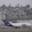

In [10]:
ds["train"][0]["img"]

## 3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)

In [11]:
from torch.utils.data import random_split

In [12]:
def split_train_val(train_data, val_size=5000, seed=42):
    """Split train_data into train and validation sets (reproducible)."""
    train_size = len(train_data) - val_size
    generator = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(train_data, [train_size, val_size], generator=generator)
    return train_set, val_set

spliting into train and val set

In [13]:
train_set, val_set = split_train_val(train_data)
print(f"Length of training set {len(train_set)} and val set {len(val_set)}")

Length of training set 45000 and val set 5000


## 4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`

In [14]:
from torch.utils.data import DataLoader

In [15]:
def make_loader(dataset, batch_size=64, shuffle=False):
    """Wrap a dataset in a DataLoader that yields batches."""
    # DataLoader groups single examples into batches of `batch_size`.
    # Each batch is collated into tensors, e.g. images (N, 3, 32, 32).
    # shuffle=True reshuffles the order at the start of every epoch
    # (use it for train only; val/test don't need it).
    # We return the loader so the caller can iterate over the batches.
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [16]:
# Training loader: serves train_set (45k examples) in batches of 64 - > 45k /64 = 704
# shuffle=True reorders the examples every epoch, so the model doesn't
# see them in the same order each time. Nothing is loaded yet; batches
# are produced (and transformed) only when we iterate over the loader.
train_loader = make_loader(train_set, shuffle=True)

In [17]:
len(train_loader)

704

Pipline

ds                 -> raw dataset from Hugging Face (PIL images)

train_data         -> ds["train"] + apply_transform (tensors on read)

train_set, val_set -> 45k / 5k split of train_data

train_loader       -> train_set served in shuffled batches of 64

In [18]:
# Validation loader: no shuffling needed, we only measure performance.
val_loader = make_loader(val_set)
len(val_loader)

79

dict from hugging face - img : label

In [19]:
test_loader = make_loader(test_data)
len(test_loader)

157

 Number of batches per loader = ceil(number of examples / batch_size).

In [20]:
print(len(train_loader), len(val_loader), len(test_loader))

704 79 157


Number of individual examples (images + labels) in each set

In [21]:
print(len(train_set), len(val_set), len(test_data))

45000 5000 10000


In [22]:
batch = next(iter(train_loader))
print(type(batch))
print(batch.keys())

<class 'dict'>
dict_keys(['img', 'label'])


## 5. `check_batch(loader)` → prints the shape of images and labels of one batch

In [38]:
def get_batch(loader):
    """Return one batch (images, labels) from the loader."""
    batch = next(iter(loader))
    return batch["img"], batch["label"]


def check_batch(loader):
    """Print the types, shapes and dtypes of one batch."""
    x, y = get_batch(loader)
    print(f"x: type={type(x)}, shape={x.shape}, dtype={x.dtype}")
    print(f"y: type={type(y)}, shape={y.shape}, dtype={y.dtype}")

In [46]:
x, y = get_batch(train_loader)
print(y.shape, x.shape)

torch.Size([64]) torch.Size([64, 3, 32, 32])


 x - a batch of 64 images, each with 3 channels (RGB) and 32 x 32 pixels
     shape (64, 3, 32, 32), dtype float32, pixel values scaled to 0-1
     
 y - 64 labels, one label per image (class index 0-9)
     shape (64,), dtype int64

## Step 2: MLP baseline and training loop
1. `get_device()` → returns `"cuda"`, `"mps"` or `"cpu"`
2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)
3. `count_parameters(model)` → returns the number of trainable parameters
4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss
5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy
6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict
7. `plot_history(history)` → plots train loss, val loss and val accuracy

**I understand it when I can explain:** each line of `train_one_epoch`, `backward()` vs `step()`, what `model.eval()` is for.

In [47]:
def get_device():
    """Return the best available device: cuda, mps or cpu."""
    if torch.cuda.is_available():            # NVIDIA GPU
        return "cuda"
    if torch.backends.mps.is_available():    # Apple Silicon GPU (Mac)
        return "mps"
    return "cpu"                             # fallback: plain processor

In [48]:
device = get_device()
device

'cpu'

# 2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)


In [49]:
import torch.nn as nn

In [51]:
def build_mlp():
    """Simple MLP: flatten -> 2 hidden layers -> class scores."""
    return nn.Sequential(
        nn.Flatten(),             # (N, 3, 32, 32) -> (N, 3072); keeps the batch dim
        nn.Linear(3072, 512),      # input size = number of values in one flat image
        nn.ReLU(),                # non-linearity between layers
        nn.Linear(512, 256),      # second hidden layer
        nn.ReLU(),
        nn.Linear(256, 10),      # output size = number of classes
    )
model = build_mlp()
out = model(x)
print(out.shape)

torch.Size([64, 10])


In [52]:
# Model output: logits
# out has shape (64, 10): for each of the 64 images, 10 raw scores,
# one per CIFAR-10 class (0 = airplane, ..., 9 = truck).
# Higher score = the model "believes" more in that class.
# These are logits, NOT probabilities: they can be negative and
# don't sum to 1. The model is untrained, so scores are close
# to each other and predictions are close to random (~10% accuracy).

print(out[0])                 # 10 scores for the first image
print(out.argmax(dim=1)[:10]) # predicted class of the first 10 images
print(y[:10])                 # true labels, for comparison

tensor([-0.1483,  0.0594, -0.1086,  0.0980, -0.0971, -0.0978, -0.0738,  0.0633,
        -0.0793,  0.0606], grad_fn=<SelectBackward0>)
tensor([3, 3, 3, 3, 3, 9, 3, 3, 3, 3])
tensor([9, 8, 8, 4, 8, 1, 1, 8, 6, 6])


In [53]:
# softmax turns the 10 logits into probabilities (0-1, sum = 1)
probs = torch.softmax(out[0], dim=0)
print(probs, probs.sum())

tensor([0.0887, 0.1092, 0.0923, 0.1135, 0.0934, 0.0933, 0.0956, 0.1096, 0.0951,
        0.1093], grad_fn=<SoftmaxBackward0>) tensor(1.0000, grad_fn=<SumBackward0>)


### Untrained model = undecided
Softmax gives ~10% to every class (1 / 10): a uniform guess, because the weights are still random.
Expected initial loss: **-ln(0.1) ≈ 2.30**.

## 3. `count_parameters(model)` → returns the number of trainable parameters


In [54]:
def count_parameters(model):
    """Return the number of trainable parameters in the model."""
    total = 0                      # running sum of parameters
    for p in model.parameters():   # every weight and bias tensor, one by one
        total += p.numel()               # number of elements in tensor p
        print(p.shape, p.numel())
    return total
count_parameters(model)

torch.Size([512, 3072]) 1572864
torch.Size([512]) 512
torch.Size([256, 512]) 131072
torch.Size([256]) 256
torch.Size([10, 256]) 2560
torch.Size([10]) 10


1707274

## 4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss

In [55]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    """Train the model for one epoch and return the mean train loss."""
    model.train()                          # training mode
    total_loss = 0.0                       # sum of per-example losses

    for batch in loader:                   # NEW: loop over all batches
        xb = batch["img"].to(device)       # NEW: images -> same device as model
        yb = batch["label"].to(device)     # NEW: labels -> same device as model

        optimizer.zero_grad()              # 1. clear old gradients
        output = model(xb)                 # 2. forward pass
        loss = loss_fn(output, yb)         # 3. compute loss
        loss.backward()                    # 4. backprop: gradients
        optimizer.step()                   # 5. update weights

        total_loss += loss.item() * xb.size(0)   # NEW: accumulate loss

    return total_loss / len(loader.dataset)      # NEW: mean loss per example

result after one epoch

In [56]:
device = get_device()
model = build_mlp().to(device)                 # model must be moved to device too
loss_fn = nn.CrossEntropyLoss()                # clasification - we have 0 classes 
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
print(train_loss)

1.865680955865648


## 5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy

In [57]:
def evaluate(model, loader, loss_fn, device):
    """Return (mean loss, accuracy) of the model on the given loader."""
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            xb = batch["img"].to(device)                   # images -> device
            yb = batch["label"].to(device)                   # labels -> device
            output = model(xb)               # forward pass
            loss = loss_fn(output, yb)
            total_loss += loss.item() * xb.size(0)          # same as in train_one_epoch
            correct += (output.argmax(dim=1) == yb).sum().item()             # how many predictions are right in this batch?
    n = len(loader.dataset)
    return total_loss / n, correct / n

acc and val loss after one epoch

In [58]:
val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
print(val_loss, val_acc)

1.7625165082931518 0.3562


## 6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict


In [59]:
def fit(model, train_loader, val_loader, epochs, lr, device):
    """Train for several epochs and return a history of the metrics."""
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)                # one epoch of training
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)        # measure on validation
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"epoch {epoch + 1}/{epochs} | train {train_loss:.3f} "
              f"| val {val_loss:.3f} | acc {val_acc:.3f}")
    return history

epochs = x * 45 k training photos

In [60]:
model = build_mlp()
history = fit(model, train_loader, val_loader, epochs=10, lr=1e-3, device=device)

epoch 1/10 | train 1.855 | val 1.724 | acc 0.381
epoch 2/10 | train 1.673 | val 1.631 | acc 0.421
epoch 3/10 | train 1.588 | val 1.579 | acc 0.434
epoch 4/10 | train 1.529 | val 1.505 | acc 0.462
epoch 5/10 | train 1.491 | val 1.509 | acc 0.455
epoch 6/10 | train 1.453 | val 1.492 | acc 0.464
epoch 7/10 | train 1.421 | val 1.544 | acc 0.452
epoch 8/10 | train 1.398 | val 1.427 | acc 0.494
epoch 9/10 | train 1.373 | val 1.444 | acc 0.486
epoch 10/10 | train 1.348 | val 1.484 | acc 0.478


## 7. `plot_history(history)` → plots train loss, val loss and val accuracy

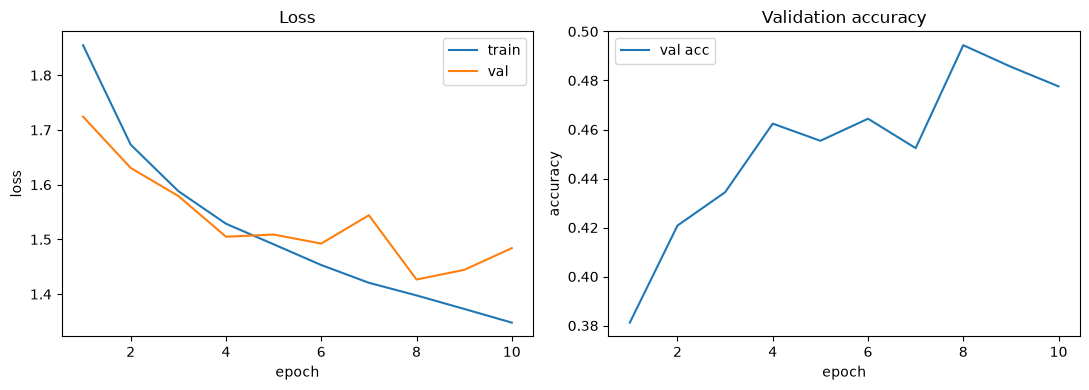

In [61]:
import matplotlib.pyplot as plt


def plot_history(history):
    """Plot train/val loss and val accuracy per epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))

    # Left panel: loss curves
    ax_loss.plot(epochs, history["train_loss"], label="train")
    ax_loss.plot(epochs, history["val_loss"], label="val")      # blank 1
    ax_loss.set_xlabel("epoch")
    ax_loss.set_ylabel("loss")
    ax_loss.set_title("Loss")
    ax_loss.legend()

    # Right panel: validation accuracy
    ax_acc.plot(epochs, history["val_acc"], label="val acc")   # blank 2
    ax_acc.set_xlabel("epoch")
    ax_acc.set_ylabel("accuracy")
    ax_acc.set_title("Validation accuracy")
    ax_acc.legend()

    plt.tight_layout()
    plt.show()


plot_history(history)

## Step 3: own CNN
1. `build_cnn()` → 3 blocks of Conv → BatchNorm → ReLU → MaxPool + Linear head
2. Before running: work out the shape after every layer on paper, then verify with `print(x.shape)`
3. Reuse `count_parameters`, `fit`, `plot_history` and compare with the MLP

**I understand it when I can explain:** where each shape comes from, why a CNN has fewer parameters than an MLP, what pooling does.

In [83]:
def build_cnn(dropout=0.0):
    """CNN: 3 x (Conv -> BatchNorm -> ReLU -> MaxPool) -> Flatten -> Linear."""
    return nn.Sequential(
        # Block 1: (3, 32, 32) -> (32, 16, 16)
        nn.Conv2d(3, 32, kernel_size=3, padding=1),    # 32 filters, size kept by padding
        nn.BatchNorm2d(32),                            # normalize each of 32 channels
        nn.ReLU(),                                     # non-linearity
        nn.MaxPool2d(2),                               # halve H and W

        # Block 2: (32, 16, 16) -> (64, 8, 8)
        nn.Conv2d(32, 64, kernel_size=3, padding=1),   # in = out of block 1
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3: (64, 8, 8) -> (128, 4, 4)
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Head: (128, 4, 4) -> 2048 -> 10 class scores
        nn.Flatten(),
        nn.Dropout(dropout),
        nn.Linear(2048, 10),
    )

In [66]:
x, y = get_batch(train_loader)
model_2 = build_cnn()
print(model_2(x).shape)          # expected: ?
print(count_parameters(model_2))

torch.Size([64, 10])
torch.Size([32, 3, 3, 3]) 864
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([64, 32, 3, 3]) 18432
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([128, 64, 3, 3]) 73728
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([10, 2048]) 20480
torch.Size([10]) 10
114186


### CNN: shape and parameter check

- Output shape: `[64, 10]` = 64 images in the batch, 10 class scores (logits) each.
- Parameters: **114,186** (MLP baseline: 1,707,274, so ~15x fewer).
- Why so few: conv filters are **shared** across the whole image (local 3x3 window),
  while an MLP needs one weight per pixel per neuron.
- Most parameters are in Conv3 (73,856); the final Linear head has 20,490.

In [67]:
history_2 = fit(model_2, train_loader, val_loader, epochs=10, lr=1e-3, device=device)

epoch 1/10 | train 1.209 | val 1.008 | acc 0.664
epoch 2/10 | train 0.840 | val 0.870 | acc 0.695
epoch 3/10 | train 0.713 | val 0.835 | acc 0.716
epoch 4/10 | train 0.618 | val 0.973 | acc 0.673
epoch 5/10 | train 0.541 | val 0.774 | acc 0.734
epoch 6/10 | train 0.473 | val 0.737 | acc 0.755
epoch 7/10 | train 0.413 | val 0.968 | acc 0.695
epoch 8/10 | train 0.364 | val 0.778 | acc 0.759
epoch 9/10 | train 0.304 | val 0.768 | acc 0.750
epoch 10/10 | train 0.269 | val 1.063 | acc 0.698


### CNN: training results (10 epochs, Adam, lr=1e-3)

| Model | Best val acc | Final val acc |
|---|---|---|
| MLP baseline | ~0.48 | ~0.48 |
| CNN | **0.759** (epoch 8) | 0.698 (epoch 10) |

**Observations**
- CNN beats the MLP by ~25 points with 15x fewer parameters.
- **Overfitting:** train loss keeps falling (1.21 -> 0.27), but val loss stops
  improving after epoch 6 (0.737) and becomes noisy (0.97, 1.06).
- The last epoch is not the best one: choose the model by **validation**, not by
  the final epoch.
- Val metrics are unstable between epochs (likely high learning rate + BatchNorm).

**Next steps (Step 4):** data augmentation, dropout, lower learning rate / scheduler,
keep the best checkpoint.

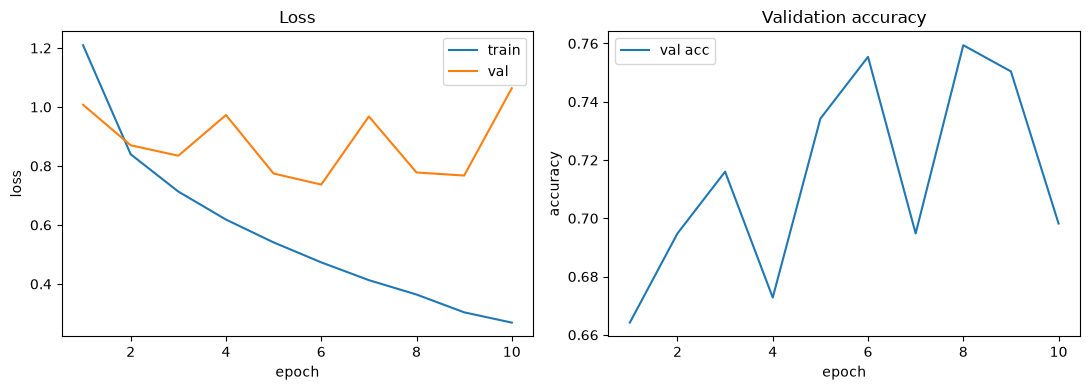

In [68]:
plot_history(history_2)

### Reading the plot: CNN learning curves

- **Left panel (loss):** train loss falls steadily (1.21 -> 0.27), while val loss
  stops improving around epoch 5-6 (~0.74) and then becomes noisy (up to 1.06).
  The widening gap between the two curves is **overfitting**.
- **Right panel (val accuracy):** rises to ~0.76 but fluctuates between epochs
  (0.67 - 0.76). The last epoch (0.698) is worse than the best one (epoch 8).
- In epoch 1 val loss is *lower* than train loss: train loss is averaged over the
  whole epoch while the model is still improving, val is measured at the end.

**Conclusions**
- The model has enough capacity to memorize the training set; more epochs alone
  will not help.
- Pick the model by **validation** performance (best epoch), not the last epoch.
- To reduce overfitting: data augmentation, dropout, weight decay.
- To stabilize training: lower learning rate or a scheduler.

## Step 4: experiments (one change at a time)
1. `build_train_transform(augment)` → returns the transform with or without augmentation (`RandomCrop`, `RandomHorizontalFlip`)
2. `build_cnn(dropout)` → CNN with an optional dropout parameter
3. `run_experiment(name, **settings)` → builds, trains, returns val accuracy and parameters
4. Compare: augmentation yes/no, dropout yes/no, two learning rates; fill the table below

**I understand it when I can explain:** how to spot overfitting on a plot and how each regularization technique works.

1. `build_train_transform(augment)` → returns the transform with or without augmentation (`RandomCrop`, `RandomHorizontalFlip`)


In [70]:
def build_train_transform(augment):
    """Return a transform for PIL images; add random augmentation if augment=True."""
    steps = []
    if augment:
        steps.append(transforms.RandomHorizontalFlip())
        steps.append(transforms.RandomCrop(32, padding=4))
    steps.append(transforms.ToTensor())
    return transforms.Compose(steps)

In [79]:
# Two transforms: random augmentation for training, deterministic for evaluation
aug_tf = build_train_transform(True)       # random flip + random crop + ToTensor
plain_tf = build_train_transform(False)    # only ToTensor (no randomness)

# Two lazy views of the SAME 50k train images (transform runs at read time)
train_aug = ds["train"].with_transform(lambda b: apply_transform(b, aug_tf))
train_plain = ds["train"].with_transform(lambda b: apply_transform(b, plain_tf))

# Test set: never augmented, untouched until the final evaluation
test_data = ds["test"].with_transform(lambda b: apply_transform(b, plain_tf))

# Same seed -> same indices in both splits, so no image is in both train and val
train_set, _ = split_train_val(train_aug)     # 45k train images, augmented
_, val_set = split_train_val(train_plain)     # 5k val images, clean

In [81]:
train_loader = make_loader(train_set, shuffle=True)
val_loader = make_loader(val_set)
test_loader = make_loader(test_data)

print(len(train_set), len(val_set))   

45000 5000


dropout created above

bulding model with dropout

In [84]:
model = build_cnn(dropout=0.3)
x, y = get_batch(train_loader)
print(model(x).shape, count_parameters(model))

torch.Size([32, 3, 3, 3]) 864
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([64, 32, 3, 3]) 18432
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([128, 64, 3, 3]) 73728
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([10, 2048]) 20480
torch.Size([10]) 10
torch.Size([64, 10]) 114186


3. `run_experiment(name, **settings)` → builds, trains, returns val accuracy and parameters


In [85]:
def run_experiment(name, augment, dropout, lr, epochs=10):
    """Build, train and evaluate one CNN configuration; return its results."""
    # Pick the training view: augmented or plain
    source = train_aug if augment else train_plain
    train_set, _ = split_train_val(source)
    train_loader = make_loader(train_set, shuffle=True)

    model = build_cnn(dropout)                       # which setting goes here?
    history = fit(model, train_loader, val_loader, epochs=epochs, lr=lr, device=device)

    return {
        "name": name,
        "best_val_acc": max(history["val_acc"]),       # best epoch, not the last one
        "params": count_parameters(model),
    }

In [86]:
import pandas as pd

# (name, augment, dropout, learning rate)
configs = [
    ("baseline",         False, 0.0, 1e-3),
    ("aug",              True,  0.0, 1e-3),
    ("aug+drop",         True,  0.3, 1e-3),
    ("aug+drop, low lr", True,  0.3, 3e-4),
]


def run_all(configs):
    """Run every configuration and return a table of results."""
    results = []
    for name, augment, dropout, lr in configs:
        print(f"--- {name} ---")
        results.append(run_experiment(name, augment, dropout, lr))
    return pd.DataFrame(results)


results = run_all(configs)
results

--- baseline ---
epoch 1/10 | train 1.199 | val 1.203 | acc 0.585
epoch 2/10 | train 0.862 | val 0.784 | acc 0.731
epoch 3/10 | train 0.724 | val 0.922 | acc 0.691
epoch 4/10 | train 0.634 | val 0.774 | acc 0.730
epoch 5/10 | train 0.555 | val 0.774 | acc 0.737
epoch 6/10 | train 0.483 | val 0.819 | acc 0.729
epoch 7/10 | train 0.421 | val 0.788 | acc 0.746
epoch 8/10 | train 0.371 | val 0.722 | acc 0.768
epoch 9/10 | train 0.324 | val 0.724 | acc 0.761
epoch 10/10 | train 0.280 | val 0.950 | acc 0.732
torch.Size([32, 3, 3, 3]) 864
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([32]) 32
torch.Size([64, 32, 3, 3]) 18432
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([64]) 64
torch.Size([128, 64, 3, 3]) 73728
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([128]) 128
torch.Size([10, 2048]) 20480
torch.Size([10]) 10
--- aug ---
epoch 1/10 | train 1.410 | val 1.258 | acc 0.574
epoch 2/10 | train 1.061 | val 1.173 | acc 0.578
epoch 3/10 | train 0.934 | val 1.049 | acc 0.643
e

,name,best_val_acc,params
0,baseline,0.7676,114186
1,aug,0.7832,114186
2,aug+drop,0.7512,114186
3,"aug+drop, low lr",0.7410,114186


**Observations**
- Augmentation gives a small gain (~+1.6 pts); with a single seed this is close to noise.
- Dropout 0.3 hurt: the network is small and, with augmentation, not strongly overfitting.
- Lower lr (3e-4) was worse: 10 epochs were not enough to converge.
- Bottleneck: training length and model capacity, not regularization.
- Selected config for later work: **augmentation, no dropout, lr=1e-3**.

## Step 5: transfer learning
1. `build_resnet18(num_classes=10, freeze=True)` → ImageNet weights, new last layer, optionally frozen body
2. Stage 1: train only the new layer (`fit`)
3. `unfreeze(model)` → makes all parameters trainable; Stage 2 with a small learning rate
4. `test_final(model, test_loader, device)` → run the test set **once**, for the single best model

**I understand it when I can explain:** why we freeze first, and why the unfrozen model uses a smaller learning rate.

---

1. `build_resnet18(num_classes=10, freeze=True)` → ImageNet weights, new last layer, optionally frozen body
2. Stage 1: train only the new layer (`fit`)

In [87]:
from torchvision import models

In [98]:
def build_resnet18(freeze=True, num_classes=10):
    """ResNet18 pretrained on ImageNet with a new classification head."""
    # Load the architecture with weights learned on ImageNet
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Freeze the backbone: the optimizer will not update these weights
    if freeze:
        for param in model.parameters():
            param.requires_grad = False

    # New head AFTER freezing: a fresh layer is trainable by default (requires_grad=True)
    model.fc = nn.Linear(512, num_classes)
    return model

In [102]:
model_3 = build_resnet18(freeze=True)
history_s1 = fit(model_3, train_loader, val_loader, epochs=3, lr=1e-3, device=device)
print(next(model_3.parameters()).requires_grad)   # first conv weight
print(model_3.fc.weight.requires_grad)            # new head
trainable = sum(p.numel() for p in model_3.parameters() if p.requires_grad)
print(trainable)

epoch 1/10 | train 1.838 | val 1.783 | acc 0.386
epoch 2/10 | train 1.725 | val 1.762 | acc 0.401
epoch 3/10 | train 1.712 | val 1.739 | acc 0.396
epoch 4/10 | train 1.706 | val 1.775 | acc 0.402
epoch 5/10 | train 1.703 | val 1.766 | acc 0.400
epoch 6/10 | train 1.695 | val 1.764 | acc 0.396
epoch 7/10 | train 1.696 | val 1.736 | acc 0.413
epoch 8/10 | train 1.693 | val 1.741 | acc 0.407
epoch 9/10 | train 1.699 | val 1.721 | acc 0.415
epoch 10/10 | train 1.693 | val 1.757 | acc 0.414
False
True
5130


3. `unfreeze(model)` → makes all parameters trainable; Stage 2 with a small learning rate

In [104]:
def unfreeze(model):
    """Make every parameter trainable again (for fine-tuning)."""
    for param in model.parameters():
        param.requires_grad = True


unfreeze(model_3)                                  # model after stage 1
history_s2 = fit(model_3, train_loader, val_loader, epochs=10, lr=1e-4, device=device)

epoch 1/10 | train 0.642 | val 0.572 | acc 0.800
epoch 2/10 | train 0.582 | val 0.545 | acc 0.810
epoch 3/10 | train 0.528 | val 0.535 | acc 0.817
epoch 4/10 | train 0.498 | val 0.535 | acc 0.819
epoch 5/10 | train 0.461 | val 0.495 | acc 0.831
epoch 6/10 | train 0.432 | val 0.499 | acc 0.832
epoch 7/10 | train 0.410 | val 0.493 | acc 0.841
epoch 8/10 | train 0.386 | val 0.486 | acc 0.844
epoch 9/10 | train 0.368 | val 0.464 | acc 0.849
epoch 10/10 | train 0.347 | val 0.485 | acc 0.847


4. `test_final(model, test_loader, device)` → run the test set **once**, for the single best model

In [ ]:
def test_final(model, test_loader, device):
    """Evaluate the chosen model on the test set. Call this ONCE, at the very end."""
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
    print(f"TEST | loss {test_loss:.3f} | acc {test_acc:.3f}")
    return test_loss, test_acc

In [ ]:
test_loss, test_acc = test_final(best_model, test_loader, device)